<a href="https://colab.research.google.com/github/chulsoo3060/YOLO_SEJONG/blob/main/YOLO_ABCD_Fair_Comparison_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
데이터셋 ZIP 3개를 업로드하세요.


Saving Bottle Detection.v1-my_bottle-70-20-10.yolov11.zip to Bottle Detection.v1-my_bottle-70-20-10.yolov11.zip
Saving my-bottle-detection.v1i.yolov11.zip to my-bottle-detection.v1i.yolov11.zip
Saving Yolo.v1i.yolov11.zip to Yolo.v1i.yolov11.zip
Train A/B/C/D: [141, 141, 141, 141]
공통 Validation: 60 공통 Test: 90

학습 시작: A_Mine
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fair_abcd/datasets/A_Mine.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, fl

,Model,Test,Precision,Recall,mAP50,mAP50-95
0,A_Mine,mine,0.9981,1.0000,0.9950,0.9190
1,A_Mine,sanghyeon,0.6699,0.6333,0.6380,0.4405
2,A_Mine,jian,0.8116,0.3333,0.4378,0.1198
3,A_Mine,all_90,0.9131,0.5838,0.7243,0.5185
4,B_Sanghyeon,mine,0.4299,0.4667,0.4060,0.1150
5,B_Sanghyeon,sanghyeon,0.9966,1.0000,0.9950,0.8779
6,B_Sanghyeon,jian,0.7745,0.7333,0.8043,0.5235
7,B_Sanghyeon,all_90,0.7576,0.7294,0.7761,0.5260
8,C_Jian,mine,0.4258,0.2333,0.2504,0.1600
9,C_Jian,sanghyeon,0.7238,0.6333,0.6957,0.4418


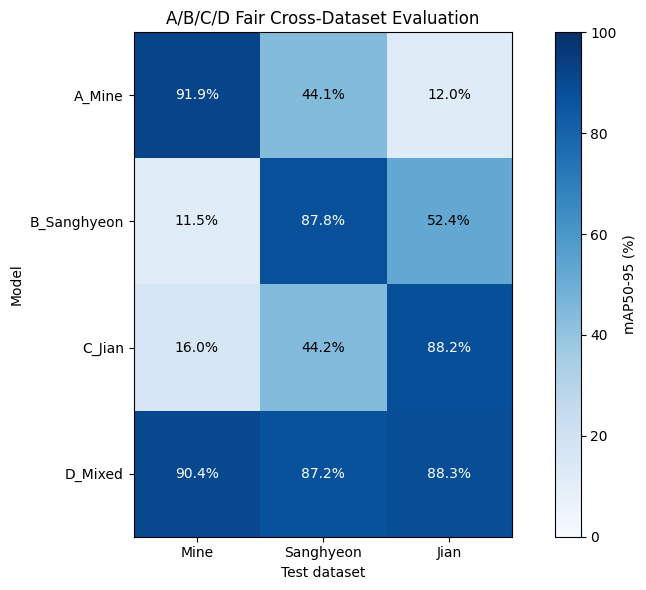

,Macro_mean_pct,Worst_pct,Best_pct,Std_pct,Pooled_90_pct
Model,,,,,
A_Mine,49.31,11.98,91.90,40.22,51.85
B_Sanghyeon,50.55,11.50,87.79,38.17,52.60
C_Jian,49.46,16.00,88.19,36.38,49.94
D_Mixed,88.65,87.21,90.40,1.62,88.38


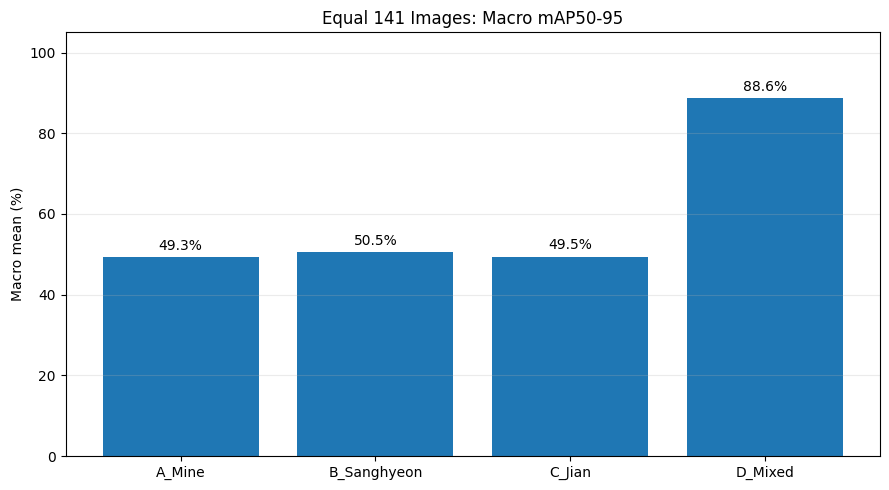

완료! 가중치 4개: /content/drive/MyDrive/YOLO_Fair_ABCD 
결과 ZIP: /content/YOLO_ABCD_Fair_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from pathlib import Path
%pip install -q ultralytics pyyaml
import zipfile, shutil, random, hashlib, yaml
import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from google.colab import files, drive
from IPython.display import display

SEED = 42
PEOPLE = ['mine', 'sanghyeon', 'jian']
ROOT = Path('/content/fair_abcd')
WORK = ROOT / 'datasets'
RESULTS = ROOT / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), 'Colab에서 T4 GPU를 활성화하세요.'
drive.mount('/content/drive')
SAVE = Path('/content/drive/MyDrive/YOLO_Fair_ABCD')
SAVE.mkdir(parents=True, exist_ok=True)

print('데이터셋 ZIP 3개를 업로드하세요.')
uploaded = files.upload()
def zip_by_prefix(prefix):
    matches = [x for x in uploaded if x.lower().startswith(prefix.lower()) and x.lower().endswith('.zip')]
    if len(matches) != 1:
        raise ValueError(f'{prefix} 파일 확인: {matches}')
    return Path('/content') / matches[0]
zip_paths = {
    'mine': zip_by_prefix('my-bottle-detection'),
    'sanghyeon': zip_by_prefix('yolo.'),
    'jian': zip_by_prefix('bottle detection'),
}

def read_dataset(person, archive):
    dest = ROOT / 'originals' / person
    if dest.exists(): shutil.rmtree(dest)
    dest.mkdir(parents=True)
    with zipfile.ZipFile(archive) as z: z.extractall(dest)
    yamls = list(dest.rglob('data.yaml'))
    assert len(yamls) == 1, f'{person}의 data.yaml 확인 필요: {yamls}'
    folder = yamls[0].parent
    config = yaml.safe_load(yamls[0].read_text(encoding='utf-8'))
    names = config.get('names')
    if isinstance(names, dict):
        names = [v for _, v in sorted(names.items(), key=lambda kv: int(kv[0]))]
    assert names == ['my_bottle'], f'{person} 클래스 확인: {names}'
    records = []
    for split in ('train', 'valid', 'test'):
        image_dir = folder / split / 'images'
        label_dir = folder / split / 'labels'
        assert image_dir.is_dir() and label_dir.is_dir(), f'{person}/{split} 폴더 오류'
        for image in sorted(image_dir.iterdir()):
            if image.suffix.lower() not in ('.jpg','.jpeg','.png'): continue
            label = label_dir / (image.stem + '.txt')
            assert label.is_file(), f'라벨 파일 없음: {label}'
            records.append((person, image, label))
    assert len(records) == 201, f'{person} 이미지 수 확인: {len(records)}'
    return records

# 공통 Test/Validation을 먼저 고정하고 남은 사진만 Train 후보로 사용
all_data = {p: read_dataset(p, zip_paths[p]) for p in PEOPLE}
rng = random.Random(SEED)
parts = {}
for person in PEOPLE:
    items = list(all_data[person]); rng.shuffle(items)
    parts[person] = {
        'test': items[:30],
        'val': items[30:50],
        'pool': items[50:],
    }
    assert len(parts[person]['pool']) == 151

trains = {
    'A_Mine': parts['mine']['pool'][:141],
    'B_Sanghyeon': parts['sanghyeon']['pool'][:141],
    'C_Jian': parts['jian']['pool'][:141],
    'D_Mixed': [r for p in PEOPLE for r in parts[p]['pool'][:47]],
}
assert all(len(v) == 141 for v in trains.values())
common_val = [r for p in PEOPLE for r in parts[p]['val']]
common_test = [r for p in PEOPLE for r in parts[p]['test']]

# 정확히 같은 이미지가 Train/Val/Test에 겹치면 중지
seen = {}
for split, records in [('train', [r for v in trains.values() for r in v]),
                       ('val', common_val), ('test', common_test)]:
    for p, im, lbl in records:
        digest = hashlib.sha256(im.read_bytes()).hexdigest()
        if digest in seen and seen[digest] != split:
            raise ValueError(f'중복 이미지가 Train/Val/Test에 걸쳐 있습니다: {im}')
        seen[digest] = split

print('Train A/B/C/D:', [len(x) for x in trains.values()])
print('공통 Validation:', len(common_val), '공통 Test:', len(common_test))

if WORK.exists(): shutil.rmtree(WORK)
WORK.mkdir(parents=True)

def copy_records(records, split):
    imdir = WORK / split / 'images'; labdir = WORK / split / 'labels'
    imdir.mkdir(parents=True, exist_ok=True)
    labdir.mkdir(parents=True, exist_ok=True)
    for person, img, label in records:
        stem = person + '_' + img.stem
        target_im = imdir / (stem + img.suffix)
        target_lb = labdir / (stem + '.txt')
        assert not target_im.exists() and not target_lb.exists(), f'이름 중복: {stem}'
        shutil.copy2(img, target_im); shutil.copy2(label, target_lb)

copy_records(common_val, 'val')
copy_records(common_test, 'test_all')
for person in PEOPLE: copy_records(parts[person]['test'], 'test_' + person)
for name, recs in trains.items(): copy_records(recs, 'train_' + name)

def make_yaml(name, train_folder, test_folder):
    file = WORK / (name + '.yaml')
    cfg = {'path':str(WORK), 'train':train_folder+'/images',
           'val':'val/images', 'test':test_folder+'/images',
           'names':{0:'my_bottle'}}
    file.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding='utf-8')
    return str(file)

train_yaml = {k:make_yaml(k,'train_'+k,'test_all') for k in trains}
test_yaml = {p:make_yaml('test_'+p,'train_A_Mine','test_'+p) for p in PEOPLE}
test_yaml['all_90'] = make_yaml('test_all_90','train_A_Mine','test_all')

manifest = []
for name, items in trains.items():
    manifest += [{'model':name,'split':'train','domain':p,'filename':im.name}
                 for p, im, lbl in items]
for split, items in [('val',common_val),('test',common_test)]:
    manifest += [{'model':'ALL','split':split,'domain':p,'filename':im.name}
                 for p, im, lbl in items]
pd.DataFrame(manifest).to_csv(RESULTS/'split_manifest.csv', index=False)

# 모두 동일 사전학습 모델에서 처음부터 학습 (예전 A/B/C best.pt 재사용 X)
weights = {}
for name in trains:
    print('\n학습 시작:', name)
    model = YOLO('yolo11n.pt')
    result = model.train(data=train_yaml[name], epochs=50, imgsz=640,
                         batch=16, device=0, seed=42, deterministic=True,
                         optimizer='SGD', lr0=0.01, momentum=0.937,
                         patience=100, workers=2,
                         project=str(ROOT/'runs'), name=name,
                         exist_ok=True, plots=True)
    best = Path(result.save_dir)/'weights'/'best.pt'
    assert best.exists(), f'가중치 없음: {best}'
    out = SAVE/('best_'+name+'.pt')
    shutil.copy2(best, out)
    weights[name] = str(out)

# Test 30장씩 평가, pooled 90장도 별도 평가
rows = []
for name, file in weights.items():
    model = YOLO(file)
    for test, config in test_yaml.items():
        m = model.val(data=config, split='test', imgsz=640, batch=1,
                      device=0, plots=False, verbose=False,
                      project=str(ROOT/'eval'), name=name+'_on_'+test,
                      exist_ok=True)
        rows.append({'Model':name,'Test':test,
                     'Precision':float(m.box.mp),
                     'Recall':float(m.box.mr),
                     'mAP50':float(m.box.map50),
                     'mAP50-95':float(m.box.map)})

df = pd.DataFrame(rows)
df.to_csv(RESULTS/'ABCD_results.csv', index=False)
display(df.round(4))

matrix = (df[df.Test.isin(PEOPLE)]
          .pivot(index='Model',columns='Test',values='mAP50-95')
          .reindex(index=list(trains),columns=PEOPLE)*100)
fig,ax = plt.subplots(figsize=(9,6))
im = ax.imshow(matrix.values, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(3),['Mine','Sanghyeon','Jian'])
ax.set_yticks(range(4),list(trains))
for i in range(4):
    for j in range(3):
        v = matrix.iloc[i,j]
        ax.text(j,i,f'{v:.1f}%',ha='center',va='center',
                color='white' if v>=55 else 'black')
ax.set(title='A/B/C/D Fair Cross-Dataset Evaluation',xlabel='Test dataset',ylabel='Model')
fig.colorbar(im,ax=ax,label='mAP50-95 (%)')
fig.tight_layout(); fig.savefig(RESULTS/'ABCD_heatmap.png',dpi=200)
plt.show()

summary = (df[df.Test.isin(PEOPLE)].groupby('Model')['mAP50-95']
           .agg(['mean','min','max','std'])*100)
summary.columns=['Macro_mean_pct','Worst_pct','Best_pct','Std_pct']
summary['Pooled_90_pct'] = (df[df.Test=='all_90'].set_index('Model')['mAP50-95']*100)
summary=summary.reindex(list(trains))
summary.to_csv(RESULTS/'ABCD_summary.csv')
display(summary.round(2))
fig, ax = plt.subplots(figsize=(9,5))
bars=ax.bar(summary.index,summary['Macro_mean_pct'])
ax.bar_label(bars,fmt='%.1f%%',padding=3)
ax.set(title='Equal 141 Images: Macro mAP50-95',ylabel='Macro mean (%)',ylim=(0,105))
ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(RESULTS/'ABCD_macro_comparison.png',dpi=200)
plt.show()

package=Path('/content/YOLO_ABCD_Fair_Results.zip')
with zipfile.ZipFile(package,'w',zipfile.ZIP_DEFLATED) as z:
    for f in RESULTS.iterdir(): z.write(f,arcname=f.name)
print('완료! 가중치 4개:',SAVE,'\n결과 ZIP:',package)
files.download(str(package))